Name : Aishi De Sec : A Sem : 7 PRN : 23070521008 Batch : A1


AIM : Credit Card Fraud Detection using Deep Learning. Problem Statement: Detect fraudulent
credit card transactions using deep neural networks. Activities: Handle imbalanced data;
Train classification model; Evaluate precision, recall, and F1-score.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

# Generate synthetic credit card data (99.8% Legitimate, 0.2% Fraudulent)
X_raw, y_raw = make_classification(
    n_samples=50000,
    n_features=30,
    n_informative=20,
    n_redundant=10,
    weights=[0.998, 0.002],
    flip_y=0,
    random_state=42
)

# Create DataFrame
feature_cols = [f"V{i}" for i in range(1, 30)] + ["Amount"]
df = pd.DataFrame(X_raw, columns=feature_cols)
df['Class'] = y_raw

fraud_count = df['Class'].sum()
total_count = len(df)
print(f"Total Transactions: {total_count}")
print(f"Fraudulent Transactions: {fraud_count} ({fraud_count/total_count*100:.2f}%)")
print(f"Legitimate Transactions: {total_count - fraud_count}")

Total Transactions: 50000
Fraudulent Transactions: 100 (0.20%)
Legitimate Transactions: 49900


In [ ]:
# Separate features and target
X = df.drop(columns=['Class']).values
y = df['Class'].values

# Split into Train (80%) and Test (20%) using stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standardize numerical features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Calculate class weights to handle severe class imbalance
neg_count = np.sum(y_train == 0)
pos_count = np.sum(y_train == 1)

weight_for_0 = (1 / neg_count) * (len(y_train) / 2.0)
weight_for_1 = (1 / pos_count) * (len(y_train) / 2.0)

class_weight = {0: weight_for_0, 1: weight_for_1}
print(f"Weight for Legitimate (Class 0): {weight_for_0:.2f}")
print(f"Weight for Fraud (Class 1): {weight_for_1:.2f}")

Weight for Legitimate (Class 0): 0.50
Weight for Fraud (Class 1): 250.00


In [ ]:
# Define Deep Neural Network Architecture
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name='accuracy'),
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

model.summary()

# Train with class weights
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=256,
    validation_split=0.2,
    class_weight=class_weight,
    verbose=1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,993 (19.50 KB)

 Trainable params: 4,801 (18.75 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.8760 - auc: 0.5644 - loss: 0.7917 - precision: 0.0043 - recall: 0.2833 - val_accuracy: 0.8779 - val_auc: 0.7475 - val_loss: 0.5149 - val_precision: 0.0082 - val_recall: 0.4000
Epoch 2/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7878 - auc: 0.7130 - loss: 0.5962 - precision: 0.0043 - recall: 0.4833 - val_accuracy: 0.8359 - val_auc: 0.8274 - val_loss: 0.4863 - val_precision: 0.0106 - val_recall: 0.7000
Epoch 3/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.7524 - auc: 0.8013 - loss: 0.5173 - precision: 0.0053 - recall: 0.7000 - val_accuracy: 0.7926 - val_auc: 0.8431 - val_loss: 0.4958 - val_precision: 0.0102 - val_recall: 0.8500
Epoch 4/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.7548 - auc: 0.8797 - loss: 0.4347 - precision: 0.0061 - recall: 0.8000 - val_accuracy: 0.8161 - val_auc: 0.8526 - val_loss: 0.4464 - val_precision: 0.0114 - val_recall: 0.8500
Epoch 5/20
125/125 ━━━━━━━━━

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

--- Detailed Classification Report ---
              precision    recall  f1-score   support

  Legitimate       1.00      0.98      0.99      9980
       Fraud       0.08      0.85      0.14        20

    accuracy                           0.98     10000
   macro avg       0.54      0.91      0.57     10000
weighted avg       1.00      0.98      0.99     10000



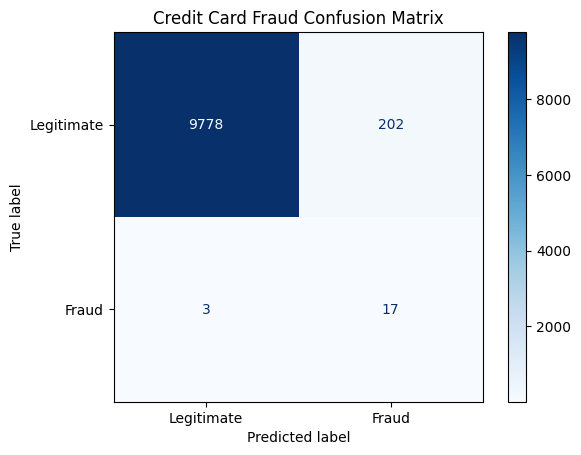

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Model predictions (probabilities -> binary class at 0.5 threshold)
y_probs = model.predict(X_test)
y_pred = (y_probs > 0.5).astype("int32")

# Classification Report
print("\n--- Detailed Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['Legitimate', 'Fraud']))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Legitimate', 'Fraud'])
disp.plot(cmap=plt.cm.Blues, values_format='d')
plt.title('Credit Card Fraud Confusion Matrix')
plt.grid(False)
plt.show()

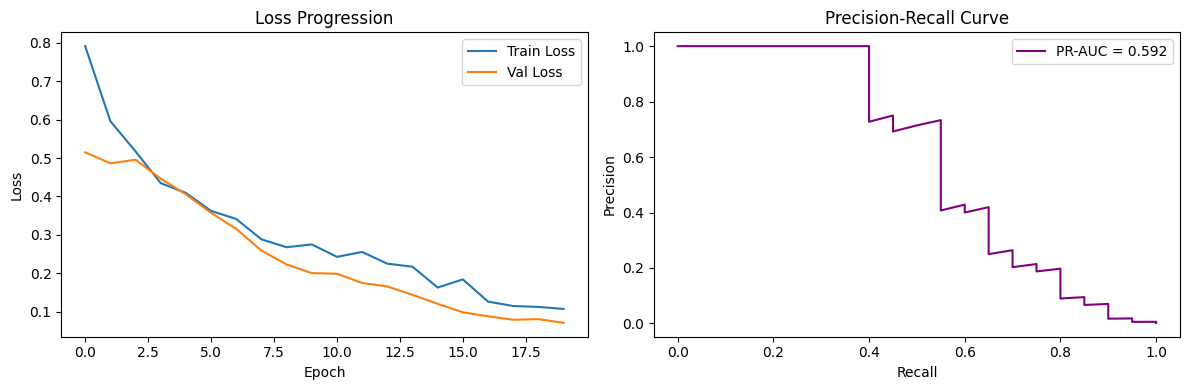

In [ ]:
from sklearn.metrics import precision_recall_curve, auc

# Compute Precision-Recall curve
precisions, recalls, _ = precision_recall_curve(y_test, y_probs)
pr_auc = auc(recalls, precisions)

plt.figure(figsize=(12, 4))

# Training vs Validation Loss
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss Progression')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Precision-Recall Curve
plt.subplot(1, 2, 2)
plt.plot(recalls, precisions, color='purple', label=f'PR-AUC = {pr_auc:.3f}')
plt.title('Precision-Recall Curve')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend()

plt.tight_layout()
plt.show()